MARTINGALE STRATEGY
Initial bankroll = 100
Base bet = 1
Table maximum = 64
Maximum allowed bets = 6
Maximum session loss = 63

THEORETICAL RESULTS
P(small profit) = 0.9816637187679195
P(large loss) = 0.018336281232080497
Small profit = 1
Large loss = -63
Expected profit per session = -0.1735219988531519

MONTE CARLO RESULTS
Number of sessions = 1000000
Simulated P(small profit) = 0.981576
Theoretical P(small profit) = 0.9816637187679195
Simulated P(large loss) = 0.018424
Theoretical P(large loss) = 0.018336281232080497
Simulated mean profit = -0.179136
Theoretical expected profit = -0.1735219988531519
Simulated variance = 74.07434229350405

Theoretical variance = 73.72825404480942
Standard error of mean = 0.00858651582685372
Difference = -0.005614001146848097
Difference in standard errors = -0.6538159668081791

PASS: Monte Carlo mean agrees with theoretical expectation.

FINITE BANKROLL COMPARISON

 Bankroll  Allowed_Bets  Small_Profit_Probability  Large_Loss_Probability  Large_Loss  E

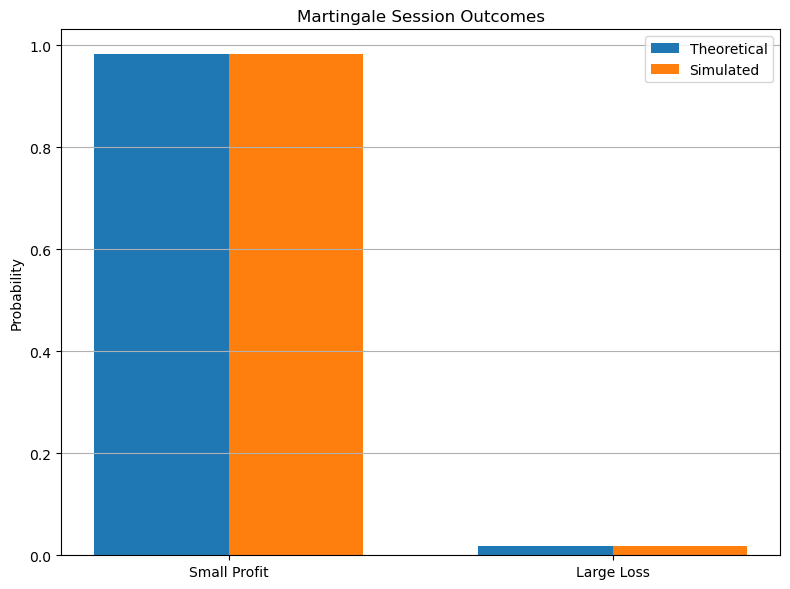

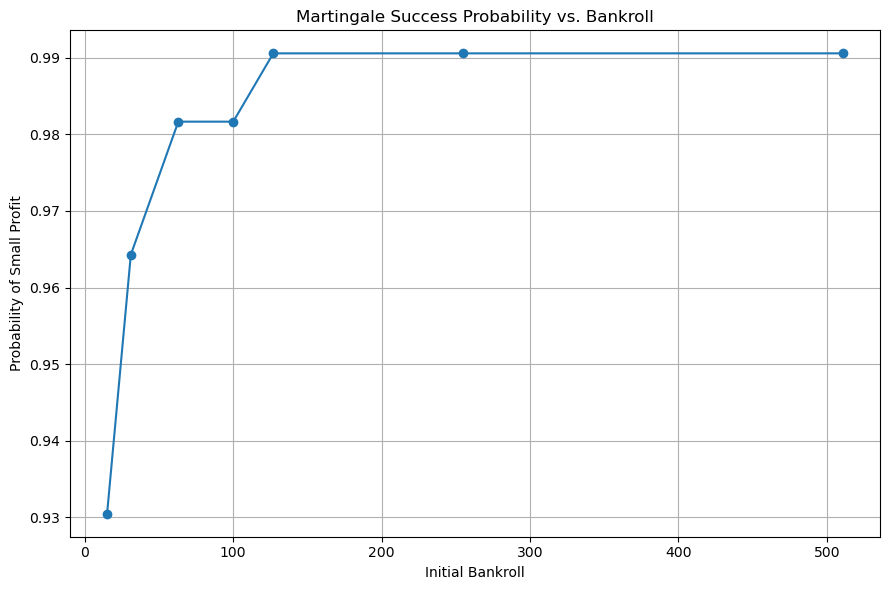

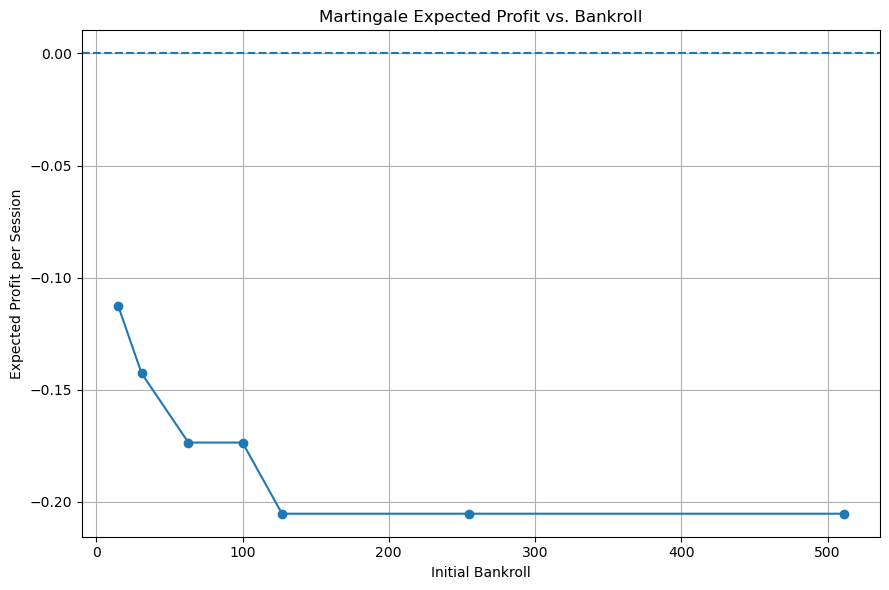

In [1]:
# ============================================================
# HOMEWORK 2.2 - PART IV
# MARTINGALE / LOSS-CHASING STRATEGY
# STANDALONE VERIFICATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# SETTINGS
# ============================================================

NUM_SESSIONS = 1_000_000

SEED = 42

BASE_BET = 1

INITIAL_BANKROLL = 100

TABLE_MAX = 64


# European roulette probabilities

P_WIN = 18 / 37

P_LOSS = 19 / 37


# ============================================================
# DETERMINE NUMBER OF ALLOWED MARTINGALE BETS
# ============================================================

def max_martingale_bets(
    bankroll,
    base_bet,
    table_max
):

    bet = base_bet

    money_remaining = bankroll

    number_of_bets = 0


    while (
        bet <= money_remaining
        and
        bet <= table_max
    ):

        number_of_bets += 1

        money_remaining -= bet

        bet *= 2


    return number_of_bets


k = max_martingale_bets(
    INITIAL_BANKROLL,
    BASE_BET,
    TABLE_MAX
)


max_loss = (
    BASE_BET
    *
    (2**k - 1)
)


print("=" * 65)

print(
    "MARTINGALE STRATEGY"
)

print("=" * 65)

print(
    "Initial bankroll =",
    INITIAL_BANKROLL
)

print(
    "Base bet =",
    BASE_BET
)

print(
    "Table maximum =",
    TABLE_MAX
)

print(
    "Maximum allowed bets =",
    k
)

print(
    "Maximum session loss =",
    max_loss
)


# ============================================================
# THEORETICAL RESULTS
# ============================================================

p_large_loss = (
    P_LOSS ** k
)


p_small_profit = (
    1
    -
    p_large_loss
)


small_profit = BASE_BET


large_loss = -max_loss


expected_profit = (

    p_small_profit
    *
    small_profit

    +

    p_large_loss
    *
    large_loss
)


print()

print("=" * 65)

print(
    "THEORETICAL RESULTS"
)

print("=" * 65)

print(
    "P(small profit) =",
    p_small_profit
)

print(
    "P(large loss) =",
    p_large_loss
)

print(
    "Small profit =",
    small_profit
)

print(
    "Large loss =",
    large_loss
)

print(
    "Expected profit per session =",
    expected_profit
)


# ============================================================
# MONTE CARLO SIMULATION
#
# rng.geometric(P_WIN) gives the number of bets
# required until the first win.
#
# Example:
#
# 1 means win immediately
# 2 means one loss then win
# 3 means two losses then win
#
# If the first win requires more than k bets,
# the Martingale session fails.
# ============================================================

rng = np.random.default_rng(
    SEED
)


bet_number_of_first_win = rng.geometric(
    P_WIN,
    size=NUM_SESSIONS
)


successful_session = (
    bet_number_of_first_win
    <=
    k
)


session_profit = np.where(

    successful_session,

    small_profit,

    large_loss
)


# ============================================================
# SIMULATION RESULTS
# ============================================================

sim_p_small_profit = np.mean(
    successful_session
)


sim_p_large_loss = np.mean(
    ~successful_session
)


sim_mean_profit = np.mean(
    session_profit
)


sim_variance = np.var(
    session_profit
)


print()

print("=" * 65)

print(
    "MONTE CARLO RESULTS"
)

print("=" * 65)

print(
    "Number of sessions =",
    NUM_SESSIONS
)

print(
    "Simulated P(small profit) =",
    sim_p_small_profit
)

print(
    "Theoretical P(small profit) =",
    p_small_profit
)

print(
    "Simulated P(large loss) =",
    sim_p_large_loss
)

print(
    "Theoretical P(large loss) =",
    p_large_loss
)

print(
    "Simulated mean profit =",
    sim_mean_profit
)

print(
    "Theoretical expected profit =",
    expected_profit
)

print(
    "Simulated variance =",
    sim_variance
)


# ============================================================
# STANDARD ERROR CHECK
# ============================================================

theoretical_second_moment = (

    p_small_profit
    *
    small_profit**2

    +

    p_large_loss
    *
    large_loss**2
)


theoretical_variance = (

    theoretical_second_moment

    -

    expected_profit**2
)


standard_error = np.sqrt(

    theoretical_variance

    /

    NUM_SESSIONS
)


difference = (

    sim_mean_profit

    -

    expected_profit
)


z_score = (

    difference

    /

    standard_error
)


print()

print(
    "Theoretical variance =",
    theoretical_variance
)

print(
    "Standard error of mean =",
    standard_error
)

print(
    "Difference =",
    difference
)

print(
    "Difference in standard errors =",
    z_score
)


if abs(z_score) < 4:

    print()

    print(
        "PASS: Monte Carlo mean agrees "
        "with theoretical expectation."
    )

else:

    print()

    print(
        "WARNING: Simulation differs "
        "from theory more than expected."
    )


# ============================================================
# BANKROLL COMPARISON
# ============================================================

bankroll_values = [
    15,
    31,
    63,
    100,
    127,
    255,
    511
]


bankroll_results = []


for bankroll in bankroll_values:

    current_k = max_martingale_bets(
        bankroll,
        BASE_BET,
        TABLE_MAX
    )


    current_max_loss = (
        BASE_BET
        *
        (2**current_k - 1)
    )


    current_p_loss = (
        P_LOSS ** current_k
    )


    current_p_profit = (
        1
        -
        current_p_loss
    )


    current_ev = (

        current_p_profit
        *
        BASE_BET

        -

        current_p_loss
        *
        current_max_loss
    )


    bankroll_results.append({

        "Bankroll":
            bankroll,

        "Allowed_Bets":
            current_k,

        "Small_Profit_Probability":
            current_p_profit,

        "Large_Loss_Probability":
            current_p_loss,

        "Large_Loss":
            -current_max_loss,

        "Expected_Profit":
            current_ev

    })


bankroll_df = pd.DataFrame(
    bankroll_results
)


print()

print("=" * 65)

print(
    "FINITE BANKROLL COMPARISON"
)

print("=" * 65)

print()

print(
    bankroll_df.to_string(
        index=False
    )
)


# ============================================================
# OUTCOME PLOT
# ============================================================

outcome_names = [
    "Small Profit",
    "Large Loss"
]


theoretical_probs = [
    p_small_profit,
    p_large_loss
]


simulated_probs = [
    sim_p_small_profit,
    sim_p_large_loss
]


x = np.arange(
    len(outcome_names)
)


width = 0.35


plt.figure(
    figsize=(8, 6)
)


plt.bar(

    x - width / 2,

    theoretical_probs,

    width,

    label="Theoretical"
)


plt.bar(

    x + width / 2,

    simulated_probs,

    width,

    label="Simulated"
)


plt.xticks(
    x,
    outcome_names
)


plt.ylabel(
    "Probability"
)


plt.title(
    "Martingale Session Outcomes"
)


plt.grid(
    True,
    axis="y"
)


plt.legend()


plt.tight_layout()


plt.savefig(
    "martingale_outcome_probabilities.png",
    dpi=300
)


plt.show()


# ============================================================
# BANKROLL VS SUCCESS PROBABILITY
# ============================================================

plt.figure(
    figsize=(9, 6)
)


plt.plot(

    bankroll_df[
        "Bankroll"
    ],

    bankroll_df[
        "Small_Profit_Probability"
    ],

    marker="o"
)


plt.xlabel(
    "Initial Bankroll"
)


plt.ylabel(
    "Probability of Small Profit"
)


plt.title(
    "Martingale Success Probability vs. Bankroll"
)


plt.grid(
    True
)


plt.tight_layout()


plt.savefig(
    "martingale_success_vs_bankroll.png",
    dpi=300
)


plt.show()


# ============================================================
# BANKROLL VS EXPECTED PROFIT
# ============================================================

plt.figure(
    figsize=(9, 6)
)


plt.plot(

    bankroll_df[
        "Bankroll"
    ],

    bankroll_df[
        "Expected_Profit"
    ],

    marker="o"
)


plt.axhline(
    0,
    linestyle="--"
)


plt.xlabel(
    "Initial Bankroll"
)


plt.ylabel(
    "Expected Profit per Session"
)


plt.title(
    "Martingale Expected Profit vs. Bankroll"
)


plt.grid(
    True
)


plt.tight_layout()


plt.savefig(
    "martingale_expected_profit_vs_bankroll.png",
    dpi=300
)


plt.show()